# 天勤 TqSdk：期货算法交易

原书 Oanda 流水线包括：注册账户 → 连接 API → 获取历史数据 → 回测 → 订阅实时行情 → 自动下单 → 查询账户。

本笔记基于现实条件，采用天勤量化 TqSdk 作为教学工具。

接口以官方文档为准：https://doc.shinnytech.com

本笔记仅供学习，不构成投资建议。


## 期货基本概念

- 期货是交易所标准化的远期交易合约。螺纹钢报价单位为元/吨；一手对应 10 吨，该数值称为合约乘数，由期货交易所在合约规则中规定。手数表示买入或卖出的合约数量。做多期望价格上涨，做空期望价格下跌。
- 名义价值 = 开仓价 × 乘数 × 手数，表示持仓对应的标的货值。保证金 ≈ 名义价值 × 保证金率，为账户预先冻结的资金。盈亏按整份名义货值计算：`(平仓价 - 开仓价) × 乘数 × 手数`。
- 代码约定：`entry` / `exit_` 为开仓价与平仓价；`lots` 为手数；`side=+1` 表示做多，`-1` 表示做空；`margin_rate=0.10` 为示意保证金率。当行情字段不可用时，才采用示意价格 3100 元/吨与乘数 10。

## 0. 准备

本节使用的天勤工具：
- `tqsdk.cfg` + `TqAuth`：快期账户用户名与密码。对应 Oanda 的 account id 与 token。
- `TqApi`：后续行情、回测与下单均挂载于该会话。对应 Oanda 的 API 连接。
- `TqSim`：本地模拟账户，初始资金可设（本笔记常用 100 万元）。进程内假账本，无用户名与密码；行情仍依赖上方快期 `TqAuth`。对应 Oanda 的 Practice 模拟盘。后续示例均显式传入 `account=TqSim(...)`，不依赖隐式默认。

使用步骤：

1. 在 https://www.shinnytech.com/products/tqsdk 注册快期账户。
2. 于笔记本同目录创建 `tqsdk.cfg`（请勿提交至 Git）：

```ini
[tqsdk]
user = 快期用户名
password = 快期密码
```

3. 安装：`pip install tqsdk -i https://mirrors.aliyun.com/pypi/simple`


In [1]:
# !pip install tqsdk -i https://mirrors.aliyun.com/pypi/simple

In [2]:
import time
from datetime import date
from pathlib import Path
import configparser

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
"""
TqAuth                 快期账户认证
    ↓
TqApi                  行情与交易会话
    ├─ account = TqSim()      本地模拟账户（本笔记默认）
    ├─ account = TqKq()       快期服务器端模拟盘
    ├─ account = TqAccount()  期货公司实盘账户
    └─ backtest = TqBacktest()  可选：历史回放
TargetPosTask(api, 合约)      按目标持仓调整仓位
"""
from tqsdk import TqApi, TqAuth, TqSim, TqBacktest, TargetPosTask

plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei", "SimHei", "PingFang SC", "Noto Sans CJK SC", "Arial Unicode MS"
]
plt.rcParams["axes.unicode_minus"] = False
pd.options.display.float_format = "{:,.4f}".format

CFG_PATH = Path("tqsdk.cfg")
config = configparser.ConfigParser()
if not config.read(CFG_PATH, encoding="utf-8"):
    raise FileNotFoundError(f"未找到 {CFG_PATH.resolve()}，请先完成 tqsdk.cfg 配置")

TQ_USER = config.get("tqsdk", "user", fallback="").strip()
TQ_PASS = config.get("tqsdk", "password", fallback="").strip()
if not TQ_USER or not TQ_PASS:
    raise ValueError("tqsdk.cfg 中 [tqsdk] 的 user / password 不能为空")

MAIN_SYMBOL = "KQ.m@SHFE.rb"  # 螺纹钢主力连续：仅用于行情；下单使用 underlying_symbol


def make_api(**kwargs):
    # TqSim 为本地假账本，无用户名密码；仍须 TqAuth 链接行情。
    kwargs.setdefault("account", TqSim(init_balance=1_000_000))
    return TqApi(auth=TqAuth(TQ_USER, TQ_PASS), **kwargs)


print("已读取凭证：", TQ_USER)


已读取凭证： 故乡的原风景


在使用天勤量化之前，默认您已经知晓并同意以下免责条款，如果不同意请立即停止使用：https://www.shinnytech.com/blog/disclaimer/


## 1. 合约一览

本节使用的天勤接口：
- `api.query_quotes`：按交易所筛选未到期合约。对应 Oanda 的 `get_instruments()`。
- `api.get_quote`：获取指定合约的盘口与静态信息（乘数、最小变动价位、最新价）。对应 Oanda 对单个 instrument 的报价查询。
- `quote.underlying_symbol`：将主力连续映射为当前可交易的月份合约。Oanda 外汇无对应概念。

国内期货按到期月分别挂牌，每张合约代码为 `交易所.品种代码+到期年月`：
- `SHFE`：上海期货交易所
- `rb`：螺纹钢
- `2701`：2027 年 1 月到期

因此 `SHFE.rb2701` 表示上期所螺纹钢 2027 年 1 月合约；下单只能针对此类具体月份合约。

若研究长期历史时仅使用单一月份合约，该合约到期后价格序列将中断。天勤提供主力连续代码 `KQ.m@SHFE.rb`：将各阶段成交最活跃的月份合约衔接为连续序列，便于获取长区间 K 线。该代码仅为行情合成标识，不可作为下单标的。当前应交易的月份合约，可通过 `get_quote("KQ.m@SHFE.rb").underlying_symbol` 查询（例如 `SHFE.rb2701`）。


In [3]:
with make_api(account=TqSim(init_balance=1_000_000)) as api: # make_api 为上下文管理器（context manager），保障 api 的生命周期
    symbols = api.query_quotes(ins_class="FUTURE", exchange_id="SHFE", expired=False)
    main_q = api.get_quote(MAIN_SYMBOL)
    TRADE_SYMBOL = main_q.underlying_symbol or next(s for s in symbols if s.startswith("SHFE.rb"))
    q = api.get_quote(TRADE_SYMBOL)
    MULTIPLIER = q.volume_multiple
    LAST_PRICE = q.last_price
    print("\n上期所在市合约：", len(symbols), "个")
    print("前 5 个：", symbols[:5])
    print("当前合约：", TRADE_SYMBOL, q.instrument_name)
    print("合约乘数：", MULTIPLIER, "| 最小变动价位：", q.price_tick)
    print("最新价：", LAST_PRICE, '\n')


2026-10-11 16:59:48 -     INFO - 通知 : 与 wss://free-api.shinnytech.com/t/nfmd/front/mobile 的网络连接已建立

上期所在市合约： 238 个
前 5 个： ['SHFE.ad2610', 'SHFE.ad2611', 'SHFE.ad2612', 'SHFE.ad2701', 'SHFE.ad2702']
当前合约： SHFE.rb2701 螺纹2701
合约乘数： 10.0 | 最小变动价位： 1.0
最新价： 3097 

2026-10-11 16:59:48 -     INFO - 模拟交易成交记录, 账户: TQSIM
2026-10-11 16:59:48 -     INFO - 模拟交易账户资金, 账户: TQSIM
2026-10-11 16:59:48 -     INFO - 日期: 2026-10-12, 账户权益: 1000000.00, 可用资金: 1000000.00, 浮动盈亏: 0.00, 持仓盈亏: 0.00, 平仓盈亏: 0.00, 市值: 0.00, 保证金: 0.00, 手续费: 0.00, 风险度: 0.00%
2026-10-11 16:59:48 -     INFO - 胜率: 0.00%, 盈亏额比例: inf, 收益率: 0.00%, 年化收益率: 0.00%, 最大回撤: 0.00%, 年化夏普率: inf,年化索提诺比率: -15.8114


## 2. 历史 K 线

本节使用的天勤接口：
- `api.get_kline_serial(合约, 周期秒数, 条数)`：获取 K 线并返回 DataFrame（`datetime/open/high/low/close/volume`）。对应 Oanda 的 `get_history()`。
- `seconds=86400` 表示日线；非交易时段亦可获取历史数据。

第 3 节向量化回测以本节返回的数据表作为输入。


In [4]:
def fetch_klines(symbol, seconds=86400, n=1500):
    with make_api(account=TqSim(init_balance=1_000_000)) as api:
        k = api.get_kline_serial(symbol, seconds, data_length=n)
        k = k[k["close"].notna()].copy() # 粗略地删除空白行
    if k.empty:
        raise RuntimeError(f"未能获取 {symbol} 的 K 线数据")

    t = (
        pd.to_datetime(k["datetime"], unit="ns", utc=True)
        .dt.tz_convert("Asia/Shanghai")
        .dt.tz_localize(None)
    )

    return pd.DataFrame(
        {"open": k["open"].values,
         "high": k["high"].values,
         "low": k["low"].values,
         "close": k["close"].values,
         "volume": k["volume"].values
        },
        index=pd.Index(t, name="time"),
    )


data = fetch_klines(MAIN_SYMBOL, seconds=86400, n=1500)


2026-10-11 16:59:49 -     INFO - 通知 : 与 wss://free-api.shinnytech.com/t/nfmd/front/mobile 的网络连接已建立


In [5]:
print(data.shape)
print(data.index.min().date(), "→", data.index.max().date())

(1500, 5)
2020-07-31 → 2026-10-12


In [6]:
data.head(3)

,open,high,low,close,volume
time,,,,,
2020-07-31,"3,772.0000","3,780.0000","3,722.0000","3,777.0000","1,159,218.0000"
2020-08-03,"3,768.0000","3,845.0000","3,762.0000","3,836.0000","1,105,480.0000"
2020-08-04,"3,843.0000","3,857.0000","3,828.0000","3,840.0000","704,824.0000"


In [7]:
data.tail(3)

,open,high,low,close,volume
time,,,,,
2026-10-08,"3,096.0000","3,100.0000","3,060.0000","3,061.0000","770,052.0000"
2026-10-09,"3,070.0000","3,094.0000","3,065.0000","3,080.0000","817,831.0000"
2026-10-12,"3,081.0000","3,105.0000","3,080.0000","3,097.0000","271,754.0000"


## 3. 向量化回测：动量窗口

本节不引入新的天勤下单接口。行情数据来自上一节的 `get_kline_serial`，对应 Oanda 章节中对 `get_history()` 结果进行 pandas 回测。

工具说明：
- `momentum`：供后续天勤主循环调用，每根已完成的 K 线计算一次方向信号。
- `backtest_momentum`：以整列 `rolling` / `shift` 完成向量化回测，对应原书第 4 章 `MomVectorBacktester`；该函数不属于 Oanda 交易 API。


In [8]:
def momentum(closes, window):
    # 仅使用已完成的收盘价
    # 依据最近 window 根平均涨跌计算方向信号
    closes = np.asarray(closes, dtype=float)
    if len(closes) < window + 1:
        return 0
    logs = np.log(closes[-(window + 1):])
    return int(np.sign(np.diff(logs).mean()))


def backtest_momentum(close, window, cost_bps=2.0, leverage=1.0):
    # 向量化回测：信号、持仓与盈亏均为整列一次计算完成
    # cost_bps：单边成本，单位为基点。1 基点 = 万分之一。默认 2 表示换手 1 倍名义时扣除 0.02% 的对数收益
    buyhold_ret = np.log(close).diff()
    signal = np.sign(buyhold_ret.rolling(window).mean()).fillna(0.0)
    pos = signal.shift(1).fillna(0.0)
    turnover = pos.diff().abs().fillna(pos.abs()) * leverage
    strategy_ret = pos * buyhold_ret * leverage - turnover * cost_bps / 1e4
    return pd.DataFrame({
        "buyhold_ret": buyhold_ret,
        "signal": signal,
        "pos": pos,
        "strategy_ret": strategy_ret,
    })


def perf_stats(net, periods=252):
    net = net.dropna()
    curve = np.exp(net.cumsum())
    ann_ret = net.mean() * periods
    ann_vol = net.std() * np.sqrt(periods)
    return {
        "年化收益": ann_ret,
        "年化波动": ann_vol,
        "夏普": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "最大回撤": (curve / curve.cummax() - 1).min(),
    }


In [9]:
W = 20
vec = backtest_momentum(data["close"], W)
print(vec.tail())

            buyhold_ret  signal     pos  strategy_ret
time                                                 
2026-09-29      -0.0003 -1.0000 -1.0000       -0.0001
2026-09-30       0.0023 -1.0000 -1.0000       -0.0023
2026-10-08      -0.0165 -1.0000 -1.0000        0.0165
2026-10-09       0.0062 -1.0000 -1.0000       -0.0062
2026-10-12       0.0055 -1.0000 -1.0000       -0.0055


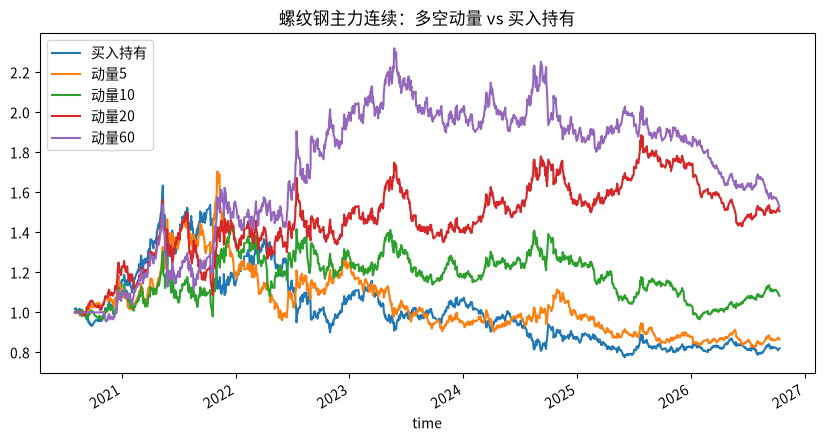

,年化收益,年化波动,夏普,最大回撤
买入持有,-0.0334,0.2209,-0.1511,-0.5255
动量5,-0.0245,0.2207,-0.1109,-0.5145
动量10,0.0133,0.2208,0.0604,-0.3281
动量20,0.0687,0.2204,0.3119,-0.3044
动量60,0.0714,0.2194,0.3256,-0.3408


In [10]:
windows = [5, 10, 20, 60]
curves = {"买入持有": np.exp(np.log(data["close"]).diff().cumsum())}
rows = {"买入持有": perf_stats(np.log(data["close"]).diff())}
for w in windows:
    bt = backtest_momentum(data["close"], w, cost_bps=2.0)
    curves[f"动量{w}"] = np.exp(bt["strategy_ret"].cumsum())
    rows[f"动量{w}"] = perf_stats(bt["strategy_ret"])

pd.DataFrame(curves).dropna().plot(figsize=(10, 5), title="螺纹钢主力连续：多空动量 vs 买入持有")
plt.show()
pd.DataFrame(rows).T

## 4. 杠杆与保证金

原书本节以 Oanda 的 CFD（差价合约）说明杠杆：账户仅缴纳保证金，盈亏却按更大的名义本金结算。基于现实条件，本笔记改用国内商品期货。二者结构相同：
- 保证金交易
- 名义价值远大于实际占用资金
- 价格的小幅波动会被放大为账户权益的大幅盈亏

后续向量化回测得到的是价格口径收益率，不可直接视为本金收益率。保证金率 10% 对应约 10 倍杠杆（`1 / 0.10`）；标的价格逆向变动 3% 时，占用保证金的亏损约为 `3% × 10 = 30%`。当亏损接近维持保证金水平时，期货公司可实施强制平仓；极端行情下亏损可能超过账户权益。因此，手数选择与回测结论均应按保证金口径解释。

本节涉及的天勤字段：
- `quote.last_price`：最新价，用作示意开仓价
- `quote.volume_multiple`：合约乘数

下文以这两个字段计算名义价值、保证金与盈亏。账户实际占用保证金，可在开仓后通过 `api.get_account().margin` 查询。期货术语与代码约定见文首「期货基本概念」。


In [11]:
def futures_pnl(entry, exit_, multiplier, margin_rate, lots=1, side=+1): # Profit and Loss
    notional = entry * multiplier * lots                                 # 名义价值：开仓价 × 合约乘数 × 手数
    margin = notional * margin_rate                                      # 保证金：按名义价值 × 保证金率预先占用的资金
    pnl = side * (exit_ - entry) * multiplier * lots                     # 盈亏：(平仓价-开仓价)×乘数×手数；side=+1 做多，-1 做空
    return {
        "名义价值": notional,
        "占用保证金": margin,
        "盈亏": pnl,
        "相对保证金收益率": pnl / margin,
        "相对名义价值收益率": pnl / notional,
    }


entry = float(LAST_PRICE) if pd.notna(LAST_PRICE) else 3100.0  # 优先采用第 1 节行情；不可用时使用螺纹钢示意价 3100 元/吨
mult = float(MULTIPLIER) if pd.notna(MULTIPLIER) else 10.0     # 螺纹钢合约乘数为 10 吨/手
print("入场价", entry, "乘数", mult, "做多 5 手，保证金率 10%")

for exit_ in [entry * 1.03, entry * 0.97, entry * 0.90]:
    r = futures_pnl(entry, exit_, multiplier=mult, margin_rate=0.10, lots=5)
    shown = {k: round(v, 3) if abs(v) < 5 else round(v) for k, v in r.items()}
    print(f"平仓 {exit_:.0f}:", shown)

入场价 3097.0 乘数 10.0 做多 5 手，保证金率 10%
平仓 3190: {'名义价值': 154850, '占用保证金': 15485, '盈亏': 4646, '相对保证金收益率': 0.3, '相对名义价值收益率': 0.03}
平仓 3004: {'名义价值': 154850, '占用保证金': 15485, '盈亏': -4646, '相对保证金收益率': -0.3, '相对名义价值收益率': -0.03}
平仓 2787: {'名义价值': 154850, '占用保证金': 15485, '盈亏': -15485, '相对保证金收益率': -1.0, '相对名义价值收益率': -0.1}


## 5. 流式行情

本节使用的天勤接口：
- `api.get_quote`：订阅盘口行情。
- `api.wait_update()`：阻塞等待业务数据更新。对应 Oanda 的 `stream_data()`。
- `api.is_changing(quote, 字段)`：判断最新价或买卖一价是否发生变化。

仅在交易时段才会出现新成交；非交易时段将先输出当前盘口，并在等待时长结束后返回。


In [12]:
def stream_quote(symbol, seconds=15):
    with make_api(account=TqSim(init_balance=1_000_000)) as api:
        quote = api.get_quote(symbol)
        print("盘口",
              quote.datetime,
              "，最新", quote.last_price,
              "，买一", quote.bid_price1,
              "，卖一", quote.ask_price1
             )

        deadline = time.time() + seconds
        n = 0
        while time.time() < deadline:
            api.wait_update(deadline=deadline)
            if api.is_changing(quote, ["last_price", "bid_price1", "ask_price1"]):
                n += 1
                print(quote.datetime,
                      "，最新", quote.last_price,
                      "，买一", quote.bid_price1,
                      "，卖一", quote.ask_price1)
        if n == 0:
            print(f"{seconds} 秒内无新成交（非交易时段常见）。")


stream_quote(TRADE_SYMBOL, seconds=15)


2026-10-11 16:59:51 -     INFO - 通知 : 与 wss://free-api.shinnytech.com/t/nfmd/front/mobile 的网络连接已建立
盘口 2026-10-09 22:59:59.500002 ，最新 3097 ，买一 3096 ，卖一 3097
2026-10-09 22:59:59.500002 ，最新 3097 ，买一 3096 ，卖一 3097
2026-10-11 17:00:06 -     INFO - 模拟交易成交记录, 账户: TQSIM
2026-10-11 17:00:06 -     INFO - 模拟交易账户资金, 账户: TQSIM
2026-10-11 17:00:06 -     INFO - 日期: 2026-10-12, 账户权益: 1000000.00, 可用资金: 1000000.00, 浮动盈亏: 0.00, 持仓盈亏: 0.00, 平仓盈亏: 0.00, 市值: 0.00, 保证金: 0.00, 手续费: 0.00, 风险度: 0.00%
2026-10-11 17:00:06 -     INFO - 胜率: 0.00%, 盈亏额比例: inf, 收益率: 0.00%, 年化收益率: 0.00%, 最大回撤: 0.00%, 年化夏普率: inf,年化索提诺比率: -15.8114


## 6. TqBacktest：动量策略的事件驱动回测

本节使用的天勤工具：
- `TqBacktest(start, end)`：将 `wait_update` 的推进方式切换为历史回放。Oanda 章节无对等官方回测引擎，原书以 pandas 或事件循环自行模拟。
- `make_api(account=..., backtest=..., disable_print=True)`：在统一入口上挂模拟账户与回测引擎；`disable_print=True` 关闭 TqSim 逐笔成交与每日资金的屏幕输出（走 `api._print`，不是 logging）。
- `TargetPosTask.set_target_volume`：按目标手数调整持仓。对应 Oanda 的 `create_order()`。
- `BacktestFinished`：回测结束时抛出的异常。
- 回测合约必须为区间内真实存在的月份合约，不可使用主力连续代码。


In [13]:
def run_momentum_backtest(symbol, start, end, window=20, bar_seconds=3600, lots=1, init_balance=1_000_000):
    """动量策略的 TqBacktest 事件驱动回测。方向信号来自 momentum()，不是通用回测框架。"""
    from tqsdk.exceptions import BacktestFinished

    with make_api(
        account=TqSim(init_balance=init_balance), # 回测函数允许调用方改初始资金
        backtest=TqBacktest(start_dt=start, end_dt=end), # 必须显式传，默认没有回测引擎，不传就还是实时时间。
        disable_print=True,  # 关闭 TqSim 逐笔成交/每日资金的屏幕输出
    ) as api:
        klines = api.get_kline_serial(symbol, bar_seconds, data_length=window + 20)
        print(klines.head(3))
        account = api.get_account()
        target = TargetPosTask(api, symbol)
        log = []
        try:
            while True:
                api.wait_update()
                # iloc[-1]：最后一行＝当前还没走完的那根 K；datetime 变了说明新 bar 刚开始
                if api.is_changing(klines.iloc[-1], "datetime"):
                    # iloc[:-1]：切片去掉最后一行，只用已收盘的 close。-1 不是做空
                    sig = momentum(klines["close"].iloc[:-1].values, window)
                    target.set_target_volume(sig * lots)
                    log.append((pd.to_datetime(klines["datetime"].iloc[-1], unit="ns"), sig, account.balance))
        except BacktestFinished:
            pass
    return pd.DataFrame(log, columns=["time", "signal", "balance"]).set_index("time")


In [14]:
BT_SYMBOL = "SHFE.rb2510"  # 2025-03 至 2025-06 期间可交易的螺纹钢合约

In [15]:
bt_log = run_momentum_backtest(BT_SYMBOL,
                      date(2025, 3, 1),
                      date(2025, 6, 30),
                      window=20,
                      bar_seconds=3600,
                      lots=1
                     )

                        datetime       id       open       high        low  \
0 1,740,099,600,000,000,000.0000 593.0000 3,414.0000 3,421.0000 3,411.0000   
1 1,740,103,200,000,000,000.0000 594.0000 3,414.0000 3,418.0000 3,409.0000   
2 1,740,106,800,000,000,000.0000 595.0000 3,416.0000 3,418.0000 3,408.0000   

       close      volume      open_oi     close_oi       symbol  duration  
0 3,414.0000 10,166.0000 239,075.0000 240,226.0000  SHFE.rb2510      3600  
1 3,416.0000  4,464.0000 240,226.0000 241,451.0000  SHFE.rb2510      3600  
2 3,414.0000  4,796.0000 241,451.0000 241,661.0000  SHFE.rb2510      3600  


In [16]:
bt_log

,signal,balance
time,,
2025-02-28 13:00:00,1,"1,000,000.0000"
2025-02-28 14:00:00,1,"999,827.0250"
2025-03-03 01:00:00,1,"999,737.0250"
2025-03-03 02:00:00,1,"999,957.0250"
2025-03-03 03:00:00,1,"999,887.0250"
...,...,...
2025-06-30 01:00:00,1,"1,000,593.5750"
2025-06-30 02:00:00,1,"1,000,373.5750"
2025-06-30 03:00:00,1,"1,000,393.5750"


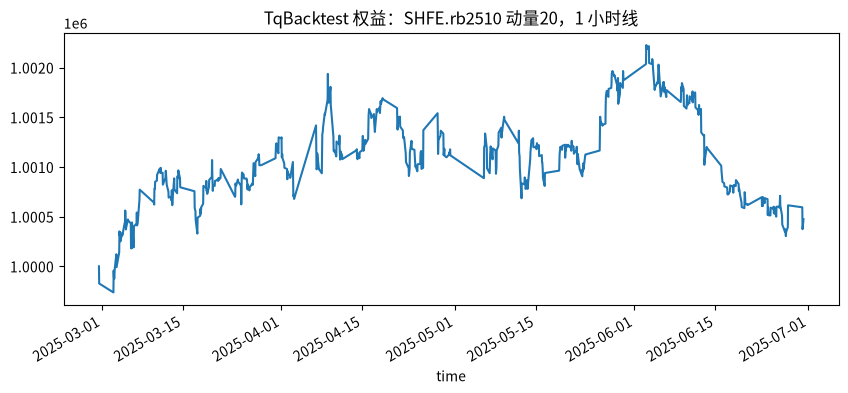

In [17]:
bt_log["balance"].plot(figsize=(10, 4), title=f"TqBacktest 权益：{BT_SYMBOL} 动量20，1 小时线")
plt.show()

## 7. 动量策略的模拟盘自动交易

本节使用的天勤工具：
- `make_api(account=TqSim(...))`：与第 6 节相同，显式挂载本地模拟账户。`TqSim` 为进程内假账本，无用户名与密码；仍须配置快期 `TqAuth` 以获取行情。若改为 `TqKq()`，则使用快期服务器端模拟盘。
- `get_kline_serial`：获取短周期 K 线。
- `wait_update`：实时主循环。对应 Oanda 章节中 `MomentumTrader` 的行情订阅。
- `TargetPosTask.set_target_volume`：对应 Oanda 的 `create_order()`。
- `get_account` / `get_position` / `get_trade`：对应 Oanda 的 `get_account_summary`、`get_transactions`。

`iloc[:-1]` 是切片：从第一根取到倒数第二根，丢掉 `iloc[-1]` 那根尚未走完的 K 线。这样动量只用已收盘价，避免盘中 `close` 一直变导致信号抖动。账户为显式传入的 `TqSim`，不涉及真实资金。


In [18]:
def account_summary(api, symbol):
    acc = api.get_account()
    pos = api.get_position(symbol)
    print("账户  权益:", f"{acc.balance:,.2f}", "可用:", f"{acc.available:,.2f}", "保证金:", f"{acc.margin:,.2f}", "手续费:", f"{acc.commission:,.2f}")
    print("持仓  多:", pos.pos_long, "手  空:", pos.pos_short, "手")
    rows = [
        {
            "成交时间": pd.to_datetime(t.trade_date_time, unit="ns"),
            "合约": t.instrument_id,
            "方向": t.direction,
            "开平": t.offset,
            "价格": t.price,
            "手数": t.volume,
        }
        for t in api.get_trade().values()
    ]
    trades = pd.DataFrame(rows)
    print("成交")
    print(trades.tail(10).to_string(index=False) if len(trades) else "（暂无成交）")
    return trades


def run_momentum_live_sim(symbol, window=6, bar_seconds=10, lots=1, run_seconds=60, init_balance=1_000_000):
    '''
    动量策略的 TqSim 模拟盘循环。方向信号来自 momentum()，不是通用 live sim。
    symbol: 合约；
    window: 动量窗口；
    bar_seconds: K 线周期；
    lots: 手数；
    run_seconds: 运行时长；
    init_balance: TqSim 初始资金（本地假账本，无用户名/密码）
    '''
    with make_api(
        account=TqSim(init_balance=init_balance),  # 显式挂本地模拟账户；无需期货公司账号密码
    ) as api:
        klines = api.get_kline_serial(symbol, bar_seconds, data_length=window + 20)     # 订阅实时 K 线，余量20根用来计算动量
        target = TargetPosTask(api, symbol)                                             # 目标持仓助手：只设目标手数，由其拆单
        deadline = time.time() + run_seconds                                            # 墙钟截止时间
        while time.time() < deadline:
            api.wait_update(deadline=deadline)
            if api.is_changing(klines.iloc[-1], "datetime"):                            # iloc[-1]＝当前未完成 K；datetime 变了=新 bar 开始
                sig = momentum(klines["close"].iloc[:-1].values, window)                # iloc[:-1]＝切掉最后一行，只用已收盘 close；-1 不是做空
                target.set_target_volume(sig * lots)                                    # 目标持仓 = 信号 × 手数
                print(pd.Timestamp.now().strftime("%H:%M:%S"), "信号", sig, "目标持仓", sig * lots)  # 打印本地时间与信号
        account_summary(api, symbol)                                                    # 结束后打印权益、持仓与最近成交


In [19]:
# 请于交易时段取消注释后运行。非交易时段通常仅输出盘口，较少产生成交。
run_momentum_live_sim(TRADE_SYMBOL, window=6, bar_seconds=10, lots=1, run_seconds=60)
print("函数已定义。开市后运行：run_momentum_live_sim(TRADE_SYMBOL)")

2026-10-11 17:00:43 -     INFO - 通知 : 与 wss://free-api.shinnytech.com/t/nfmd/front/mobile 的网络连接已建立
账户  权益: 1,000,000.00 可用: 1,000,000.00 保证金: 0.00 手续费: 0.00
持仓  多: 0 手  空: 0 手
成交
（暂无成交）
2026-10-11 17:01:43 -     INFO - 模拟交易成交记录, 账户: TQSIM
2026-10-11 17:01:43 -     INFO - 模拟交易账户资金, 账户: TQSIM
2026-10-11 17:01:43 -     INFO - 日期: 2026-10-12, 账户权益: 1000000.00, 可用资金: 1000000.00, 浮动盈亏: 0.00, 持仓盈亏: 0.00, 平仓盈亏: 0.00, 市值: 0.00, 保证金: 0.00, 手续费: 0.00, 风险度: 0.00%
2026-10-11 17:01:43 -     INFO - 胜率: 0.00%, 盈亏额比例: inf, 收益率: 0.00%, 年化收益率: 0.00%, 最大回撤: 0.00%, 年化夏普率: inf,年化索提诺比率: -15.8114
函数已定义。开市后运行：run_momentum_live_sim(TRADE_SYMBOL)


## 8. 走向实盘

本节不引入新的策略逻辑，亦不提供可执行的实盘下单代码。第 3–7 节已完成动量信号、向量化回测、事件驱动回测与 `TqSim` 模拟交易的探讨；

由模拟转入实盘，实质仅是更换 `TqApi` 所挂载的账户对象。行情订阅、`momentum`、`TargetPosTask` 与主循环均可沿用第 7 节。

此切换对应原书 Oanda 由 Practice token 过渡至 live token；在 TqSdk 中，则表现为以 `TqAccount` 取代 `TqSim`。

### 相关对象

| 对象 | 说明 |
|---|---|
| `TqAuth` | 快期认证，连接行情与交易通道（同第 0 节） |
| `TqSim` | 本地模拟账户；本笔记默认配置，不涉及真实资金 |
| `TqAccount` | 期货公司实盘账户（公司代码、资金账号、交易密码） |
| `TqApi(account=...)` | 会话入口；`account` 决定委托发往模拟或实盘 |

### 凭证

凭证放在同目录下的 `tqsdk.cfg` 里面，结构如下：

```ini
[tqsdk]
user = 快期用户名
password = 快期密码

[futures]
broker = 期货公司代码 # 支持列表见：https://www.shinnytech.com/articles/reference/tqsdk-brokers
account = 资金账号
password = 交易密码
```

`[tqsdk]` 标识快期身份，`[futures]` 标识期货公司资金账户，二者职责不同。

### 实施步骤

1. 在模拟环境完成全链路验证：历史 K 线、向量化回测、 事件驱动回测、仿真，并确认信号、仓位与周期参数合理。
2. 开立期货公司账户，确认其支持 TqSdk 或 CTP 接入。免费版快期可绑定的实盘数量以官网规则为准。
3. 将前文中的 `account=TqSim(...)` 替换为 `account=TqAccount(...)`。策略循环无需重写，变更仅限于资金账户绑定。

### 账户切换示意

1. 模拟盘：

```python
with make_api(
    account=TqSim(init_balance=1_000_000),
) as api:
    ...
```

2. 实盘：

```python
from tqsdk import TqAccount

with make_api(
    account=TqAccount(
        config.get("futures", "broker"),   # 期货公司名，如 H海通期货
        config.get("futures", "account"),
        config.get("futures", "password"),
    ),
) as api:
    ...
```

### 风险说明
实盘参数因账户而异，无法像 `TqSim` 一样统一复现；教学材料不宜附带可直接触发真实委托的入口。此外，交易时段、涨跌停、平今手续费与滑点等约束，默认回测通常未完整建模，须于上线前另行核验。

期货交易具有杠杆；极端行情下，止损委托未必按预期成交。回测或模拟结果不能外推为实盘收益。上线前应明确最大手数、单日亏损上限、断线后的处理策略，以及是否仅在交易时段运行。


## 9. 练习
1. 将第 3 节 `cost_bps` 由 2 调整为 10，对比权益曲线与绩效指标。
2. 为事件驱动回测增加规则：持仓浮亏相对开仓名义价值约达 2% 时清仓（见下方注释：为何不用账户权益 2%）。
3. 将第 7 节 `bar_seconds` 改为 60，与默认 10 秒线比较换手与手续费（须交易时段运行）。

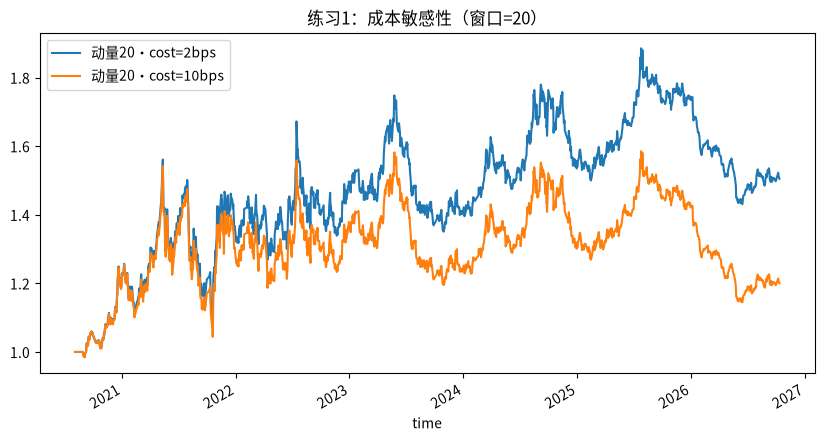

,年化收益,年化波动,夏普,最大回撤
动量20·cost=2bps,0.0687,0.2204,0.3119,-0.3044
动量20·cost=10bps,0.0307,0.2206,0.1390,-0.3231


In [20]:
# =============================================================================
# 第 9 节练习：参考实现
# =============================================================================


# ---------------------------------------------------------------------------
# 练习 1：cost_bps = 2 vs 10
# cost_bps 单位为基点：10 表示换手 1 倍名义时扣除 0.10% 的对数收益
# ---------------------------------------------------------------------------
def exercise1_cost_sensitivity(close, window=20, costs=(2.0, 10.0)):
    """同一动量窗口，不同单边成本下的曲线与绩效。"""
    curves = {}
    rows = {}
    for c in costs:
        # 直接把 cost_bps 传给第 3 节的 backtest_momentum
        bt = backtest_momentum(close, window, cost_bps=c)
        label = f"动量{window}·cost={c:g}bps"
        curves[label] = np.exp(bt["strategy_ret"].cumsum())
        rows[label] = perf_stats(bt["strategy_ret"])

    pd.DataFrame(curves).dropna().plot(
        figsize=(10, 5),
        title=f"练习1：成本敏感性（窗口={window}）",
    )
    plt.show()
    return pd.DataFrame(rows).T


# 取消下一行注释以运行练习 1（需已跑通第 2、3 节，存在 data）
exercise1_cost_sensitivity(data["close"], window=20, costs=(2.0, 10.0))

In [21]:
# ---------------------------------------------------------------------------
# 练习 2：止损用「浮亏 / 开仓名义」，不用「账户权益回撤」。
# 100 万做 1 手螺纹时，账户 2%≈2 万元，几乎触不到；名义口径约等于价格逆向 stop_loss。
# （原书 Oanda/CFD 里账户与名义更接近，账户 2% 才可能有意义。）
# ---------------------------------------------------------------------------
def run_momentum_backtest_with_stop(
    symbol,
    start,
    end,
    window=20,
    bar_seconds=3600,
    lots=1,
    init_balance=1_000_000,
    stop_loss=0.02,  # 相对开仓名义价值回撤 2% 清仓
):
    """事件驱动动量 + 名义价值口径的简易止损；仅作练习参考。"""
    from tqsdk.exceptions import BacktestFinished

    with make_api(
        account=TqSim(init_balance=init_balance),
        backtest=TqBacktest(start_dt=start, end_dt=end),
        disable_print=True,
    ) as api:
        klines = api.get_kline_serial(symbol, bar_seconds, data_length=window + 20)
        quote = api.get_quote(symbol)
        multiplier = float(quote.volume_multiple)
        account = api.get_account()
        target = TargetPosTask(api, symbol)
        log = []

        equity_at_entry = None   # 开仓时账户权益（用来算本轮盈亏金额）
        notional_at_entry = None  # 开仓名义价值 = 价 × 乘数 × 手数
        prev_pos = 0

        try:
            while True:
                api.wait_update()
                if not api.is_changing(klines.iloc[-1], "datetime"):
                    continue

                sig = momentum(klines["close"].iloc[:-1].values, window)
                desired = sig * lots

                # 空仓→开仓：记下权益与名义；基准非法则跳过开仓
                if prev_pos == 0 and desired != 0:
                    entry_price = float(klines["close"].iloc[-2])  # 刚完成的那根收盘价，作开仓价近似
                    notional = abs(entry_price * multiplier * desired)
                    if account.balance > 0 and notional > 0:
                        equity_at_entry = account.balance
                        notional_at_entry = notional
                    else:
                        desired = sig = 0
                        equity_at_entry = notional_at_entry = None

                # 持仓中：浮亏 / 开仓名义 >= stop_loss 则强平（多空同一口径）
                if desired != 0 and equity_at_entry is not None and notional_at_entry:
                    pnl = account.balance - equity_at_entry
                    if pnl / notional_at_entry <= -stop_loss:
                        desired = sig = 0

                if desired == 0:
                    equity_at_entry = notional_at_entry = None

                target.set_target_volume(desired)
                prev_pos = 0 if desired == 0 else int(np.sign(desired))

                log.append((
                    pd.to_datetime(klines["datetime"].iloc[-1], unit="ns"),
                    sig,
                    desired,
                    account.balance,
                ))
        except BacktestFinished:
            pass

    return pd.DataFrame(log, columns=["time", "signal", "target", "balance"]).set_index("time")


                        datetime       id       open       high        low  \
0 1,740,099,600,000,000,000.0000 593.0000 3,414.0000 3,421.0000 3,411.0000   
1 1,740,103,200,000,000,000.0000 594.0000 3,414.0000 3,418.0000 3,409.0000   
2 1,740,106,800,000,000,000.0000 595.0000 3,416.0000 3,418.0000 3,408.0000   

       close      volume      open_oi     close_oi       symbol  duration  
0 3,414.0000 10,166.0000 239,075.0000 240,226.0000  SHFE.rb2510      3600  
1 3,416.0000  4,464.0000 240,226.0000 241,451.0000  SHFE.rb2510      3600  
2 3,414.0000  4,796.0000 241,451.0000 241,661.0000  SHFE.rb2510      3600  


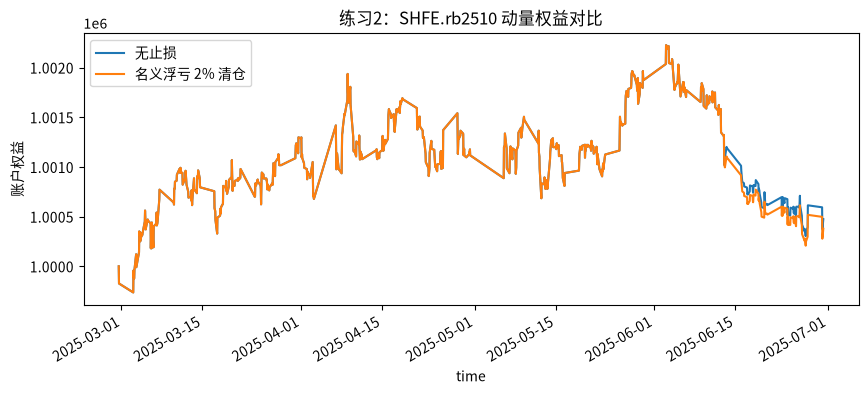

In [22]:
# 练习 2：同一区间对比「无止损」与「名义浮亏 2% 清仓」（需已定义 BT_SYMBOL）
start, end = date(2025, 3, 1), date(2025, 6, 30)
common = dict(window=20, bar_seconds=3600, lots=1)

bt_nostop = run_momentum_backtest(BT_SYMBOL, start, end, **common)
bt_stop = run_momentum_backtest_with_stop(BT_SYMBOL, start, end, stop_loss=0.02, **common)

ax = bt_nostop["balance"].plot(figsize=(10, 4), label="无止损")
bt_stop["balance"].plot(ax=ax, label="名义浮亏 2% 清仓")
ax.set_title(f"练习2：{BT_SYMBOL} 动量权益对比")
ax.set_ylabel("账户权益")
ax.legend()
plt.show()


In [23]:
# 期末权益与区间收益简表
cmp = pd.DataFrame({
    "无止损": bt_nostop["balance"],
    "名义浮亏2%": bt_stop["balance"],
}).dropna(how="all")

summary = pd.DataFrame({
    "期末权益": [cmp["无止损"].iloc[-1], cmp["名义浮亏2%"].iloc[-1]],
    "区间收益%": [
        (cmp["无止损"].iloc[-1] / cmp["无止损"].iloc[0] - 1) * 100,
        (cmp["名义浮亏2%"].iloc[-1] / cmp["名义浮亏2%"].iloc[0] - 1) * 100,
    ],
}, index=["无止损", "名义浮亏2%"])

summary

,期末权益,区间收益%
无止损,"1,000,473.5750",0.0474
名义浮亏2%,"1,000,377.6250",0.0378


In [24]:
pd.concat(
    {"无止损": bt_nostop[["signal", "balance"]], "名义浮亏2%": bt_stop[["signal", "target", "balance"]]},
    axis=1,
).tail()


无止损                名义浮亏2%                      
                    signal        balance signal target        balance
time                                                                  
2025-06-30 01:00:00      1 1,000,593.5750      1      1 1,000,497.6250
2025-06-30 02:00:00      1 1,000,373.5750      1      1 1,000,277.6250
2025-06-30 03:00:00      1 1,000,393.5750      1      1 1,000,297.6250
2025-06-30 05:00:00      1 1,000,453.5750      1      1 1,000,357.6250
2025-06-30 06:00:00      1 1,000,473.5750      1      1 1,000,377.6250

In [25]:
# ---------------------------------------------------------------------------
# 练习 3：bar_seconds=10 vs 60（须交易时段运行）
# 更短周期 → 新 bar 更频繁 → 信号可能更常翻转 → 成交与手续费通常上升
# ---------------------------------------------------------------------------
def run_momentum_live_sim_collect(symbol, window=6, bar_seconds=10, lots=1, run_seconds=60, init_balance=1_000_000):
    """与 run_momentum_live_sim 相同逻辑，额外返回手续费、成交笔数、重设目标次数。"""
    n_retarget = 0
    with make_api(account=TqSim(init_balance=init_balance)) as api:
        klines = api.get_kline_serial(symbol, bar_seconds, data_length=window + 20)
        target = TargetPosTask(api, symbol)
        deadline = time.time() + run_seconds
        while time.time() < deadline:
            api.wait_update(deadline=deadline)
            if api.is_changing(klines.iloc[-1], "datetime"):
                sig = momentum(klines["close"].iloc[:-1].values, window)
                target.set_target_volume(sig * lots)
                n_retarget += 1
                print(pd.Timestamp.now().strftime("%H:%M:%S"), "信号", sig, "目标", sig * lots)
        acc = api.get_account()
        n_trades = len(api.get_trade())
        account_summary(api, symbol)
        return {
            "bar_seconds": bar_seconds,
            "重设目标次数": n_retarget,          # 新 bar 触发的 set_target_volume 次数（retarget）
            "成交笔数": n_trades,            # 实际成交条数（可能因信号不变而少于调仓）
            "手续费": acc.commission,        # TqSim 累计手续费
            "期末权益": acc.balance,
        }


def exercise3_compare_fees(symbol, bar_list=(10, 60), **kwargs):
    """开市后运行：对每个 bar_seconds 各跑一段，返回对比表。"""
    rows = [run_momentum_live_sim_collect(symbol, bar_seconds=b, **kwargs) for b in bar_list]
    return pd.DataFrame(rows).set_index("bar_seconds")


In [26]:
# 请于交易时段取消注释后运行练习 3
fee_cmp = exercise3_compare_fees(TRADE_SYMBOL, bar_list=(10, 60), window=6, lots=1, run_seconds=60)
print(fee_cmp)

2026-10-11 17:02:57 -     INFO - 通知 : 与 wss://free-api.shinnytech.com/t/nfmd/front/mobile 的网络连接已建立
账户  权益: 1,000,000.00 可用: 1,000,000.00 保证金: 0.00 手续费: 0.00
持仓  多: 0 手  空: 0 手
成交
（暂无成交）
2026-10-11 17:03:57 -     INFO - 模拟交易成交记录, 账户: TQSIM
2026-10-11 17:03:57 -     INFO - 模拟交易账户资金, 账户: TQSIM
2026-10-11 17:03:57 -     INFO - 日期: 2026-10-12, 账户权益: 1000000.00, 可用资金: 1000000.00, 浮动盈亏: 0.00, 持仓盈亏: 0.00, 平仓盈亏: 0.00, 市值: 0.00, 保证金: 0.00, 手续费: 0.00, 风险度: 0.00%
2026-10-11 17:03:57 -     INFO - 胜率: 0.00%, 盈亏额比例: inf, 收益率: 0.00%, 年化收益率: 0.00%, 最大回撤: 0.00%, 年化夏普率: inf,年化索提诺比率: -15.8114
2026-10-11 17:03:58 -     INFO - 通知 : 与 wss://free-api.shinnytech.com/t/nfmd/front/mobile 的网络连接已建立
账户  权益: 1,000,000.00 可用: 1,000,000.00 保证金: 0.00 手续费: 0.00
持仓  多: 0 手  空: 0 手
成交
（暂无成交）
2026-10-11 17:04:58 -     INFO - 模拟交易成交记录, 账户: TQSIM
2026-10-11 17:04:58 -     INFO - 模拟交易账户资金, 账户: TQSIM
2026-10-11 17:04:58 -     INFO - 日期: 2026-10-12, 账户权益: 1000000.00, 可用资金: 1000000.00, 浮动盈亏: 0.00, 持仓盈亏: 0.00, 平仓盈亏: 0.00, 市值: 0.0